# 02 · Behavioral Change and States

**Research question (whole project):** Can changes in customer behavior be detected, described, and represented as a small set of
interpretable behavioral states — and do state-aware models stay more reliable when behavior changes?

**This notebook** covers the descriptive half: is there distribution change (§A), can behavior be summarized as states (§B), how do customers
move between states (§C), and do existing drift measures track those moves (§D).
Notebook 03 uses these states to learn transition rules and compare global vs state-aware models; notebook 04 is the product application.

Inputs: `data/processed/model_data.parquet`, `data/processed/customer_period.parquet` (notebook 01) and `data/raw/clients.csv` (card issue dates).
Output: `data/processed/customer_states.parquet` (state and boundary margin per customer-period, used by notebook 03).

## §0 · Setup

**What this does:** loads the processed table, rebuilds the *exact* 60/20/20 split used in the causal work
(same `random_state=42`, stratified on treatment × target), and adds one new variable: whether the customer's
loyalty card existed before E1.

**Why the card date matters:** a customer with zero transactions in E1 might be *inactive* — or might simply not have had a card yet.
Those are different things. Treating "not yet observable" as "inactive" would create fake *Inactive → Active* transitions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import ks_2samp
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

PERIODS = ["E1", "E2", "E3", "E4"]
PERIOD_PAIRS = [("E1", "E2"), ("E2", "E3"), ("E3", "E4")]
PERIOD_START = {"E1": "2018-11-27", "E2": "2018-12-25", "E3": "2019-01-22", "E4": "2019-02-19"}
PERIOD_END   = {"E1": "2018-12-25", "E2": "2019-01-22", "E3": "2019-02-19", "E4": "2019-03-19"}

BEHAVIOR = ["transactions", "total_spend", "avg_basket_spend",
            "total_quantity", "avg_quantity", "avg_unique_products"]

model_data = pd.read_parquet(DATA_DIR / "processed" / "model_data.parquet")

clients = pd.read_csv(DATA_DIR / "raw" / "clients.csv",
                      usecols=["client_id", "first_issue_date"],
                      parse_dates=["first_issue_date"])
model_data = model_data.merge(clients, on="client_id", how="left")

print(model_data.shape)
print("Missing card issue dates:", model_data["first_issue_date"].isna().sum())

(200039, 47)
Missing card issue dates: 0


In [2]:
# Rebuild the exact split used in notebooks 03 and 04
model_data["stratify_group"] = (model_data["treatment_flg"].astype(str) + "_"
                                + model_data["target"].astype(str))

train_idx, temp_idx = train_test_split(model_data.index, test_size=0.40, random_state=42,
                                       stratify=model_data["stratify_group"])
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, random_state=42,
                                     stratify=model_data.loc[temp_idx, "stratify_group"])

model_data["split"] = "train"
model_data.loc[val_idx, "split"] = "val"
model_data.loc[test_idx, "split"] = "test"

print(model_data["split"].value_counts())
assert (model_data["split"] == "train").sum() == 120_023
assert (model_data["split"] == "val").sum() == 40_008

split
train    120023
val       40008
test      40008
Name: count, dtype: int64


In [3]:
# Observability: did the card exist when each period began?
for p in PERIODS:
    model_data[f"enrolled_{p}"] = model_data["first_issue_date"] < pd.Timestamp(PERIOD_START[p])

model_data["enrolled_before_E1"] = model_data["enrolled_E1"]

# How many 'zero-transaction' periods are really 'card did not exist yet'?
rows = []
for p in ["E1", "E2", "E3"]:
    zero = model_data[f"transactions_{p}"] == 0
    not_yet = model_data["first_issue_date"] >= pd.Timestamp(PERIOD_END[p])
    rows.append({"period": p,
                 "zero_tx_customers": zero.sum(),
                 "card_issued_after_period": (zero & not_yet).sum(),
                 "share_not_yet_enrolled": (zero & not_yet).sum() / zero.sum()})
enrollment_check = pd.DataFrame(rows)
enrollment_check

,period,zero_tx_customers,card_issued_after_period,share_not_yet_enrolled
0,E1,42346,15304,0.361404
1,E2,36447,9543,0.261832
2,E3,27771,4039,0.145439


In [4]:
cohort = model_data["enrolled_before_E1"]
print(f"Customers with a card before E1: {cohort.sum():,} ({cohort.mean():.1%})")

zero_rates = pd.DataFrame({
    "all_customers":     [(model_data[f"transactions_{p}"] == 0).mean() for p in PERIODS],
    "enrolled_before_E1": [(model_data.loc[cohort, f"transactions_{p}"] == 0).mean() for p in PERIODS],
}, index=PERIODS)
zero_rates.round(3)

Customers with a card before E1: 177,600 (88.8%)


,all_customers,enrolled_before_E1
E1,0.212,0.152
E2,0.182,0.145
E3,0.139,0.125
E4,0.000,0.000


**What this shows.** A large fraction of early "inactive" customers did not yet have a card
(36% of E1 zeros, 26% of E2, 15% of E3). Restricting to the 88.8% of customers enrolled before E1 removes most of that.
The remaining zeros (≈15% → 12.5% → 0%) are real inactivity — except E4, where 0% is forced by how the competition sample was built.

**Decision for the rest of this notebook:** the state analysis uses the *enrolled-before-E1 cohort*. This trades some sample size
for zeros that actually mean "did not shop".

**Limitation:** card issue date is not the same as "started shopping at X5", and a customer may have used another card. It is the best available proxy.

This is the second measurement-validity finding in the project, alongside the observation-depth confound in category drift:
**part of what looks like behavioral change is a change in who is being observed.**

## §A · Population-level distribution change

**Question:** Which original behavioral features change in distribution across E1 → E4, and by how much?

**Method (simple version):**
- **Standardized mean difference (SMD)** on `log1p(feature)`: the change in mean divided by the pooled standard deviation.
  Rough guide: |SMD| < 0.1 negligible, ~0.2 small, ~0.5 medium.
  The log is used because spending is very right-skewed; on the raw scale a few huge baskets dominate the mean.
- **Kolmogorov–Smirnov (KS) statistic**: the largest vertical gap between two cumulative distribution curves (0 = identical, 1 = completely separate).
  We report the *statistic*, not the p-value: with ~100K customers per period even trivial differences give p ≈ 0.

**Three populations, to separate real behavior change from sample composition:**
1. all training customers (zeros included);
2. active customers only (≥1 transaction in that period);
3. active customers in the enrolled-before-E1 cohort.

Only training customers are used, so nothing here touches validation/test.

In [5]:
train = model_data[model_data["split"] == "train"]

def smd(a, b):
    return (b.mean() - a.mean()) / np.sqrt((a.var() + b.var()) / 2)

populations = {
    "all": (train, False),
    "active": (train, True),
    "enrolled_active": (train[train["enrolled_before_E1"]], True),
}

rows = []
for pop_name, (sub, active_only) in populations.items():
    for f in BEHAVIOR:
        for a, b in PERIOD_PAIRS:
            xa, xb = sub[f"{f}_{a}"], sub[f"{f}_{b}"]
            if active_only:
                xa = xa[sub[f"transactions_{a}"] > 0]
                xb = xb[sub[f"transactions_{b}"] > 0]
            rows.append({
                "population": pop_name, "feature": f, "pair": f"{a}→{b}",
                "n_a": len(xa), "n_b": len(xb),
                "median_a": xa.median(), "median_b": xb.median(),
                "smd_log": smd(np.log1p(xa), np.log1p(xb)),
                "ks": ks_2samp(xa, xb).statistic,
            })
shift = pd.DataFrame(rows)

shift.pivot_table(index="feature", columns=["population", "pair"], values="smd_log").round(3)

population          active                  all               enrolled_active              
pair                 E1→E2  E2→E3  E3→E4  E1→E2  E2→E3  E3→E4           E1→E2  E2→E3  E3→E4
feature                                                                                    
avg_basket_spend     0.060 -0.071  0.038  0.085  0.093  0.525           0.066 -0.068  0.039
avg_quantity        -0.015  0.063 -0.031  0.053  0.130  0.351          -0.009  0.068 -0.030
avg_unique_products -0.004  0.075 -0.044  0.059  0.137  0.349           0.002  0.080 -0.042
total_quantity      -0.012  0.099 -0.024  0.054  0.150  0.355          -0.016  0.096 -0.032
total_spend          0.042  0.002  0.024  0.081  0.112  0.504           0.038 -0.002  0.016
transactions        -0.007  0.071 -0.004  0.050  0.131  0.304          -0.016  0.064 -0.016

In [6]:
shift.pivot_table(index="feature", columns=["population", "pair"], values="ks").round(3)

population          active                  all               enrolled_active              
pair                 E1→E2  E2→E3  E3→E4  E1→E2  E2→E3  E3→E4           E1→E2  E2→E3  E3→E4
feature                                                                                    
avg_basket_spend     0.030  0.028  0.020  0.041  0.044  0.139           0.034  0.027  0.021
avg_quantity         0.007  0.031  0.017  0.029  0.051  0.139           0.005  0.032  0.016
avg_unique_products  0.006  0.036  0.021  0.029  0.053  0.139           0.007  0.037  0.020
total_quantity       0.009  0.042  0.013  0.029  0.056  0.139           0.011  0.041  0.017
total_spend          0.022  0.005  0.012  0.031  0.044  0.139           0.021  0.005  0.008
transactions         0.008  0.028  0.009  0.029  0.045  0.139           0.010  0.026  0.011

In [7]:
# Medians in original units (active, enrolled cohort)
(shift[shift["population"] == "enrolled_active"]
     .pivot_table(index="feature", columns="pair", values=["median_a", "median_b"])
     .round(1))

median_a                 median_b                
pair                   E1→E2   E2→E3   E3→E4    E1→E2   E2→E3   E3→E4
feature                                                              
avg_basket_spend       358.6   379.9   364.0    379.9   364.0   375.9
avg_quantity             6.0     6.1     6.5      6.1     6.5     6.4
avg_unique_products      5.0     5.1     5.5      5.1     5.5     5.3
total_quantity          28.0    27.0    30.0     27.0    30.0    29.0
total_spend           1633.0  1672.1  1667.0   1672.1  1667.0  1691.0
transactions             4.0     4.0     4.0      4.0     4.0     4.0

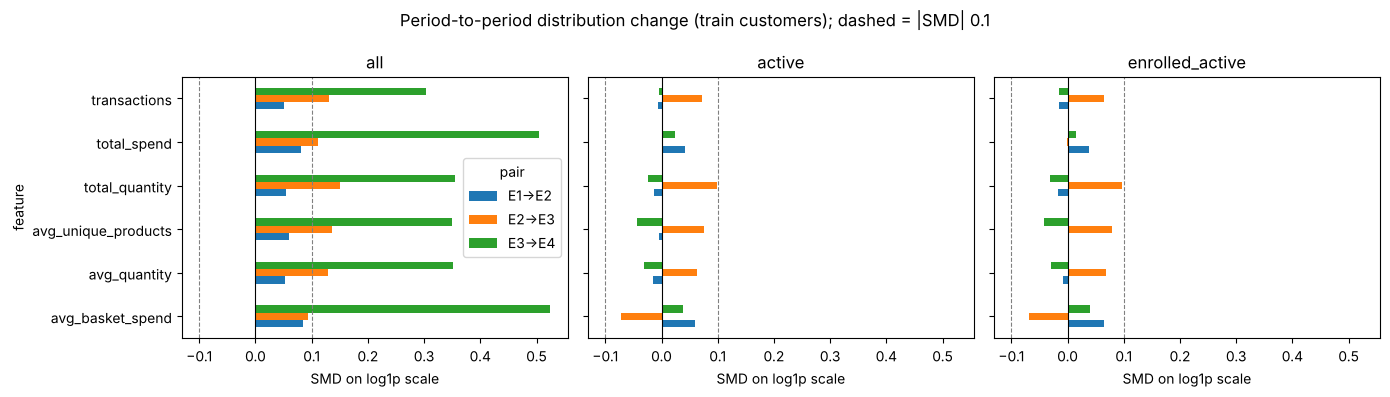

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True, sharex=True)
for ax, pop_name in zip(axes, populations):
    tab = shift[shift["population"] == pop_name].pivot(index="feature", columns="pair", values="smd_log")
    tab.plot.barh(ax=ax, legend=(pop_name == "all"))
    ax.axvline(0, color="black", lw=0.8)
    for x in (-0.1, 0.1):
        ax.axvline(x, color="grey", ls="--", lw=0.8)
    ax.set_title(pop_name)
    ax.set_xlabel("SMD on log1p scale")
fig.suptitle("Period-to-period distribution change (train customers); dashed = |SMD| 0.1")
plt.tight_layout()
plt.savefig(FIG_DIR / "A_smd_by_population.png", dpi=130)
plt.show()

**Within-customer (paired) change.** The comparisons above contrast two *crowds*. Here we follow the *same* customers:
for customers in the cohort who were active in both periods, the mean of
`log1p(x_{t+1}) − log1p(x_t)`. A value of 0.10 means roughly +10% for the typical customer.
The second number is the mean change divided by its standard deviation, i.e. how consistent the direction is across customers.

In [9]:
cohort_train = train[train["enrolled_before_E1"]]
rows = []
for a, b in PERIOD_PAIRS:
    both_active = (cohort_train[f"transactions_{a}"] > 0) & (cohort_train[f"transactions_{b}"] > 0)
    for f in BEHAVIOR:
        d = (np.log1p(cohort_train.loc[both_active, f"{f}_{b}"])
             - np.log1p(cohort_train.loc[both_active, f"{f}_{a}"]))
        rows.append({"pair": f"{a}→{b}", "feature": f, "n": both_active.sum(),
                     "mean_log_change": d.mean(), "standardized": d.mean() / d.std()})
paired = pd.DataFrame(rows)
paired.pivot(index="feature", columns="pair", values="mean_log_change").round(3)

pair,E1→E2,E2→E3,E3→E4
feature,,,
avg_basket_spend,0.043,-0.049,0.016
avg_quantity,-0.009,0.039,-0.026
avg_unique_products,-0.002,0.040,-0.028
total_quantity,-0.020,0.101,0.058
total_spend,0.032,0.011,0.107
transactions,-0.011,0.050,0.068


In [10]:
paired.pivot(index="feature", columns="pair", values="standardized").round(3)

pair,E1→E2,E2→E3,E3→E4
feature,,,
avg_basket_spend,0.067,-0.079,0.026
avg_quantity,-0.018,0.077,-0.052
avg_unique_products,-0.005,0.091,-0.064
total_quantity,-0.022,0.116,0.068
total_spend,0.032,0.012,0.113
transactions,-0.019,0.092,0.128


### §A · Interpretation

1. **The big E3 → E4 shift is mostly an artifact of who is in the sample.** Over *all* customers, E3 → E4 looks like a medium-sized
   shift (SMD ≈ 0.3–0.5; KS ≈ 0.14 for every feature). That KS of 0.139 is exactly the E3 zero-transaction share (13.9%) disappearing, because
   every competition customer is active in E4 by construction. Among **active** customers the same comparison is negligible
   (|SMD| < 0.05, KS ≈ 0.01–0.02).
2. **Among active customers, behavior is quite stable across periods.** Every |SMD| is at or below 0.1, and every KS is below 0.05.
   Medians barely move (e.g. 4 transactions in every period; median monthly spend ≈ 1,630–1,690).
3. **The small shifts that do exist have a pattern.** E2 has slightly larger baskets in spend; E2 → E3 has slightly *more* trips
   with *more* items but *lower* spend per basket. E2 contains the New Year holiday (25 Dec – 21 Jan), so this is plausibly seasonal.
   That is a hypothesis; we cannot test seasonality with one year of data.
4. **Within customers, E3 → E4 is the clearest change:** about +7% transactions and +11% spend for customers active in both periods.
   This is still partly selection: the sample requires E4 activity, which favors customers who happened to have a good E4.

**What this means for the research question.** At the population level, "distribution shift" in this dataset is mostly a change in
*participation* (who is active or observable), not a change in *how* active customers shop. Any real behavioral change must therefore be
found at the **individual** level — which motivates the state-based analysis in §B onward. This is also an honest boundary on the
project: we are looking at covariate shift P(X), and these four periods give us no way to observe a change in P(Y|X).

**Limitations:** SMD summarizes only the mean; KS is insensitive to changes in the tails; both compare marginal distributions one
feature at a time, so a change in the *joint* distribution (e.g. same trips, different mix) could be missed. §B addresses the joint view.

## §B · Behavioral states

**Question:** Can each customer-period be summarized by one of a *small* number of interpretable behavioral states?

**Population:** customers enrolled before E1 (§0). Each customer contributes four observations (E1–E4), so the unit here is the
**customer-period**.

**Two kinds of state:**
- **Inactive** — zero transactions in the period (card already issued). Defined by a rule, not learned: basket averages do not exist
  for a period with no baskets, so clustering these rows would be meaningless.
- **Active states** — learned from active customer-periods with KMeans.

**Method, step by step:**
1. **Features.** Spending and quantity totals are close to products of other features (`total_spend ≈ transactions × avg_basket_spend`),
   so clustering on all six would count the same information twice. We compare all six against a **core set of three** that are nearly
   uncorrelated and each answer a different question: *how often* (`transactions`), *how much per trip* (`avg_basket_spend`),
   *how varied the basket is* (`avg_unique_products`).
2. **`log1p` transform.** Spending is very right-skewed; on the raw scale a few huge baskets would dominate the distance calculation.
3. **`StandardScaler`.** Puts every feature on the same scale (mean 0, sd 1) so none dominates because of its units. Fit on **train rows only**.
4. **KMeans.** Places K centers and assigns each row to the nearest one, moving the centers until they sit at the middle of their groups.
   Fit on **train rows only**; validation/test rows are assigned to the nearest train center.

**How K is chosen (K = 2…6):**
- *Inertia* — total squared distance from rows to their center. Always falls as K grows; look for where the drop flattens (the "elbow").
- *Silhouette* — for each row, how much closer it is to its own cluster than the next one (−1 to 1; higher = better separated).
  Computed on a 20,000-row sample because the full calculation is slow.
- *Seed stability* — refit with different random starts; the adjusted Rand index (ARI, 1 = identical grouping) should stay near 1.
- *Train→validation stability* — fit a separate KMeans on validation rows and compare with the train model's assignments.
- *Interpretability and size* — every state should be large and describable in plain words. **This is the deciding criterion**:
  few meaningful states beat many tiny ones (the Dortmund project explicitly warns against trivial systems with too many states).

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

cohort_data = model_data[model_data["enrolled_before_E1"]].copy()

# Wide -> long: one row per customer-period
long = pd.concat([
    cohort_data[["client_id", "split"] + [f"{f}_{p}" for f in BEHAVIOR]]
        .rename(columns={f"{f}_{p}": f for f in BEHAVIOR})
        .assign(period=p)
    for p in PERIODS
], ignore_index=True)
long["active"] = long["transactions"] > 0

print("Customer-periods:", len(long), "| active:", long["active"].sum(), f"({long['active'].mean():.1%})")
long.groupby(["split", "active"]).size().unstack()

Customer-periods: 710400 | active: 635380 (89.4%)


active,False,True
split,,
test,14964,126756
train,45139,381345
val,14917,127279


In [12]:
active_train = long[long["active"] & (long["split"] == "train")]
print("Correlation of log1p features (train active rows):")
np.log1p(active_train[BEHAVIOR]).corr().round(2)

Correlation of log1p features (train active rows):


,transactions,total_spend,avg_basket_spend,total_quantity,avg_quantity,avg_unique_products
transactions,1.00,0.69,-0.13,0.74,-0.12,-0.12
total_spend,0.69,1.00,0.62,0.93,0.53,0.52
avg_basket_spend,-0.13,0.62,1.00,0.47,0.86,0.85
total_quantity,0.74,0.93,0.47,1.00,0.57,0.52
avg_quantity,-0.12,0.53,0.86,0.57,1.00,0.92
avg_unique_products,-0.12,0.52,0.85,0.52,0.92,1.00


`transactions` is almost uncorrelated with basket size (≈ −0.13), while the four "per-basket" and "total" features are strongly correlated
with each other (0.5–0.9). Behavior has two main axes: **how often** a customer shops and **how big** each trip is.

In [13]:
FEATURE_SETS = {
    "all6": BEHAVIOR,
    "core3": ["transactions", "avg_basket_spend", "avg_unique_products"],
}
active_val = long[long["active"] & (long["split"] == "val")]
sample_idx = np.random.default_rng(0).choice(len(active_train), 20_000, replace=False)

rows = []
for set_name, cols in FEATURE_SETS.items():
    scaler = StandardScaler().fit(np.log1p(active_train[cols]))
    X_tr = scaler.transform(np.log1p(active_train[cols]))
    X_va = scaler.transform(np.log1p(active_val[cols]))
    for k in range(2, 7):
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_tr)
        seed_ari = np.mean([adjusted_rand_score(km.labels_[sample_idx],
                                                KMeans(k, n_init=10, random_state=r).fit(X_tr).labels_[sample_idx])
                            for r in (1, 2)])
        km_val = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_va)
        rows.append({"features": set_name, "K": k,
                     "inertia_per_row": km.inertia_ / len(X_tr),
                     "silhouette": silhouette_score(X_tr[sample_idx], km.labels_[sample_idx]),
                     "seed_ARI": seed_ari,
                     "train_vs_val_ARI": adjusted_rand_score(km.predict(X_va), km_val.labels_),
                     "smallest_state_share": np.bincount(km.labels_).min() / len(X_tr)})
k_selection = pd.DataFrame(rows)
k_selection.round(3)

,features,K,inertia_per_row,silhouette,seed_ARI,train_vs_val_ARI,smallest_state_share
0,all6,2,3.675,0.330,0.993,0.967,0.432
1,all6,3,2.625,0.320,0.988,0.996,0.293
2,all6,4,2.103,0.311,0.992,0.969,0.191
3,all6,5,1.775,0.290,0.997,0.974,0.138
4,all6,6,1.576,0.271,0.968,0.964,0.101
5,core3,2,1.793,0.346,0.995,0.990,0.437
6,core3,3,1.296,0.338,0.994,0.986,0.272
7,core3,4,1.053,0.301,0.960,0.977,0.182
8,core3,5,0.872,0.302,0.989,0.979,0.136
9,core3,6,0.775,0.286,0.978,0.621,0.116


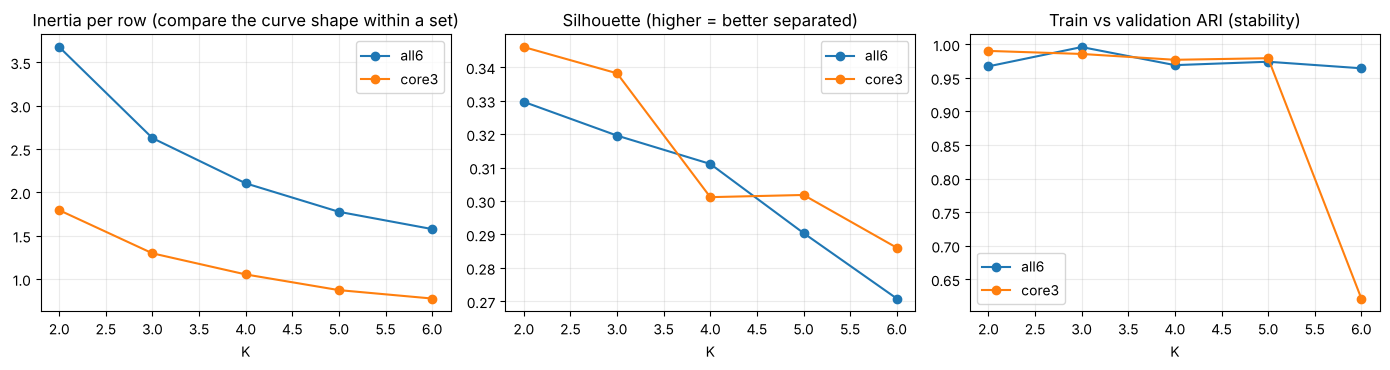

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for set_name, g in k_selection.groupby("features"):
    axes[0].plot(g["K"], g["inertia_per_row"], marker="o", label=set_name)
    axes[1].plot(g["K"], g["silhouette"], marker="o", label=set_name)
    axes[2].plot(g["K"], g["train_vs_val_ARI"], marker="o", label=set_name)
for ax, title in zip(axes, ["Inertia per row (compare the curve shape within a set)", "Silhouette (higher = better separated)",
                            "Train vs validation ARI (stability)"]):
    ax.set(title=title, xlabel="K"); ax.grid(alpha=0.25); ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "B_k_selection.png", dpi=130)
plt.show()

In [15]:
# What do the candidate solutions look like in original units? (medians per state, train rows)
def describe_states(cols, k):
    scaler = StandardScaler().fit(np.log1p(active_train[cols]))
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(scaler.transform(np.log1p(active_train[cols])))
    g = active_train.assign(state=km.labels_).groupby("state")[BEHAVIOR].median()
    g["share"] = np.bincount(km.labels_) / len(km.labels_)
    return g.sort_values(["transactions", "avg_basket_spend"]).round({**{f: 1 for f in BEHAVIOR}, "share": 3})

for k in (3, 4, 5):
    print(f"core3, K={k}")
    display(describe_states(FEATURE_SETS["core3"], k))

core3, K=3


,transactions,total_spend,avg_basket_spend,total_quantity,avg_quantity,avg_unique_products,share
state,,,,,,,
2,2.0,513.0,212.9,9.0,3.7,3.0,0.272
1,3.0,2109.9,717.7,34.0,11.4,9.0,0.367
0,9.0,2488.0,304.0,44.0,5.3,4.5,0.361


core3, K=4


,transactions,total_spend,avg_basket_spend,total_quantity,avg_quantity,avg_unique_products,share
state,,,,,,,
2,3.0,419.1,159.0,8.0,3.0,2.5,0.182
3,3.0,1194.0,432.5,20.0,7.0,6.0,0.303
1,3.0,3192.9,955.4,49.0,14.7,11.5,0.208
0,9.0,2720.0,287.2,49.0,5.1,4.3,0.307


core3, K=5


,transactions,total_spend,avg_basket_spend,total_quantity,avg_quantity,avg_unique_products,share
state,,,,,,,
2,2.0,330.0,144.8,6.0,2.7,2.2,0.136
3,2.0,929.9,376.3,15.0,6.0,5.0,0.250
4,2.0,2342.8,1008.1,36.0,15.5,12.0,0.171
1,7.0,3525.0,514.5,58.0,8.5,7.0,0.215
0,9.0,2088.0,230.8,38.0,4.2,3.6,0.227


### Choosing the states

- **No K gives sharply separated groups.** Silhouette is ≈ 0.3 everywhere. Customer behavior is a *continuum*; the states are useful
  regions of that continuum, not natural species. This matters later: a customer near a boundary can switch state with only a small
  change in behavior (checked in §C).
- **Every solution is stable** (seed and train→validation ARI ≈ 0.96–0.99), except core3 with K = 6 (validation ARI 0.62), which is a sign of over-splitting.
- **core3 is preferred over all6:** better silhouette at 4 of 5 values of K (all6 is marginally higher at K = 4), much lower redundancy, and each feature has a plain meaning.
- **K = 3 is chosen.** It is the most interpretable solution, and each larger K only subdivides an existing state by basket size:
  K = 4 adds a second "3 trips" state, K = 5 a third. Those splits are real but do not describe a different *kind* of shopping.

Together with the rule-based Inactive state, the system has **four states**.

In [16]:
STATE_FEATURES = FEATURE_SETS["core3"]
K = 3

state_scaler = StandardScaler().fit(np.log1p(active_train[STATE_FEATURES]))
state_kmeans = KMeans(n_clusters=K, n_init=10, random_state=0).fit(
    state_scaler.transform(np.log1p(active_train[STATE_FEATURES])))

# Name clusters from their centers (in original units), not by hand-picking cluster numbers
centers = pd.DataFrame(np.expm1(state_scaler.inverse_transform(state_kmeans.cluster_centers_)), columns=STATE_FEATURES)
frequent = centers["transactions"].idxmax()
rest = centers.drop(index=frequent)
stock_up = rest["avg_basket_spend"].idxmax()
light = rest.drop(index=stock_up).index[0]
STATE_NAMES = {light: "Light", stock_up: "Stock-up", frequent: "Frequent"}
STATE_ORDER = ["Inactive", "Light", "Stock-up", "Frequent"]

centers.index = centers.index.map(STATE_NAMES)
print("Cluster centers (back-transformed to original units):")
centers.loc[["Light", "Stock-up", "Frequent"]].round(1)

Cluster centers (back-transformed to original units):


,transactions,avg_basket_spend,avg_unique_products
Light,2.4,194.8,3.0
Stock-up,3.0,763.7,9.6
Frequent,9.0,292.6,4.4


In [17]:
def assign_state(df):
    """Inactive by rule; active rows -> nearest train KMeans center."""
    state = pd.Series("Inactive", index=df.index, dtype=object)
    act = df["transactions"] > 0
    labels = state_kmeans.predict(state_scaler.transform(np.log1p(df.loc[act, STATE_FEATURES])))
    state[act] = pd.Series(labels, index=df.index[act]).map(STATE_NAMES)
    return pd.Categorical(state, categories=STATE_ORDER, ordered=True)

long["state"] = assign_state(long)

profile = long.groupby("state", observed=True)[BEHAVIOR].median().round(1)
profile["share_of_customer_periods"] = long["state"].value_counts(normalize=True).reindex(STATE_ORDER).round(3)
profile

,transactions,total_spend,avg_basket_spend,total_quantity,avg_quantity,avg_unique_products,share_of_customer_periods
state,,,,,,,
Inactive,0.0,0.0,0.0,0.0,0.0,0.0,0.106
Light,2.0,511.0,212.5,9.0,3.7,3.0,0.243
Stock-up,3.0,2110.0,716.1,34.0,11.3,9.0,0.328
Frequent,9.0,2491.0,304.2,44.0,5.3,4.5,0.323


In [18]:
# State shares by split: the learned definition should transfer to validation/test
pd.crosstab(long["split"], long["state"], normalize="index").reindex(["train", "val", "test"]).round(3)

state,Inactive,Light,Stock-up,Frequent
split,,,,
train,0.106,0.243,0.328,0.323
val,0.105,0.246,0.325,0.323
test,0.106,0.242,0.328,0.324


In [19]:
# State shares by period (all splits) — how the population moves across states over time
by_period = pd.crosstab(long["period"], long["state"], normalize="index").round(3)
by_period

state,Inactive,Light,Stock-up,Frequent
period,,,,
E1,0.152,0.234,0.305,0.309
E2,0.145,0.239,0.316,0.301
E3,0.125,0.230,0.323,0.322
E4,0.000,0.271,0.368,0.361


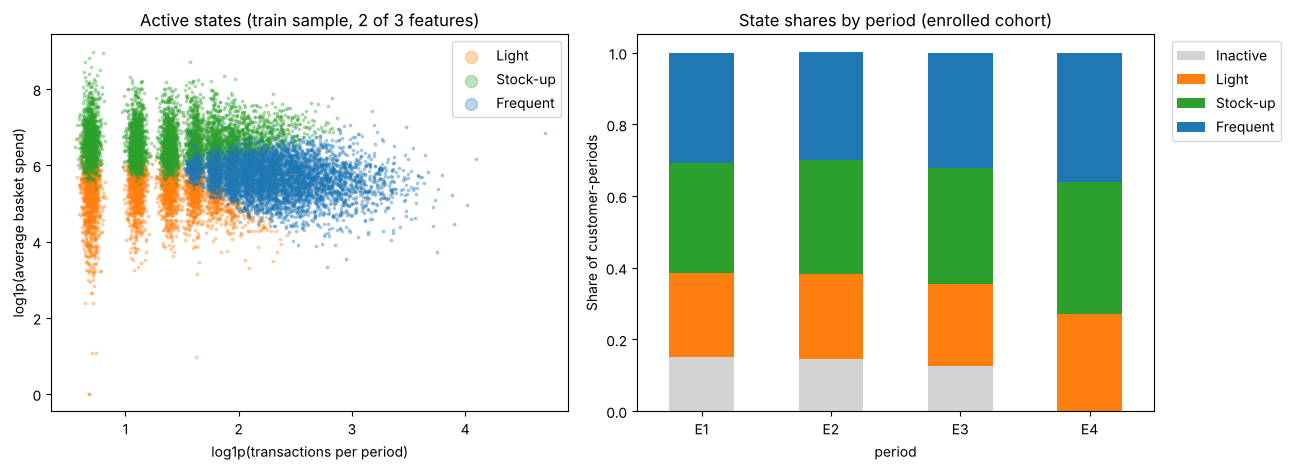

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

plot_rows = long[long["active"] & (long["split"] == "train")].sample(15_000, random_state=0)
colors = {"Light": "tab:orange", "Stock-up": "tab:green", "Frequent": "tab:blue"}
for s, c in colors.items():
    r = plot_rows[plot_rows["state"] == s]
    jitter = np.random.default_rng(1).normal(0, 0.04, len(r))
    axes[0].scatter(np.log1p(r["transactions"]) + jitter, np.log1p(r["avg_basket_spend"]), s=3, alpha=0.3, color=c, label=s)
axes[0].set(xlabel="log1p(transactions per period)", ylabel="log1p(average basket spend)",
            title="Active states (train sample, 2 of 3 features)")
axes[0].legend(markerscale=5)

by_period[STATE_ORDER].plot.bar(stacked=True, ax=axes[1], color=["lightgrey"] + list(colors.values()), rot=0)
axes[1].set(ylabel="Share of customer-periods", title="State shares by period (enrolled cohort)")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "B_states.png", dpi=130)
plt.show()

### §B · Interpretation

| State | Typical month | Share of customer-periods |
|---|---|---|
| **Inactive** | no purchases (card already issued) | 10.6% |
| **Light** | ~2 trips, small baskets (~210), ~3 distinct products | 24.3% |
| **Stock-up** | ~3 trips, large baskets (~720), ~9 distinct products | 32.8% |
| **Frequent** | ~9 trips, medium baskets (~300) | 32.3% |

Stock-up and Frequent customers spend about the same per month (~2,100 vs ~2,500) in very different ways: few large trips vs many small ones.
That distinction is invisible in a total-spend summary, which is the point of using states.

- **The state definition transfers:** state shares in validation and test match train to within 0.3 percentage points.
- **Consistent with §A:** among *active* customer-periods the Light / Stock-up / Frequent mix barely changes over time
  (E1 ≈ 28/36/36%, E4 ≈ 27/37/36%). The visible change across periods is mostly the Inactive share shrinking (15% → 0%, the last
  forced by sample selection). So the population looks stable while *individual* customers may still move between states — §C measures that.

**Limitations**
- Silhouette ≈ 0.34: the states are regions of a continuum. Customers near a boundary can change state with a small change in behavior.
- Monthly counts are small numbers (median 2–9 trips), so some period-to-period variation is ordinary randomness, not changed behavior.
- KMeans assumes roughly round clusters of similar spread in the scaled space; it was chosen because it is simple to explain and stable here,
  not because the data has that shape.
- The 28-day period length is fixed by the data design; a different window would give somewhat different states.

## §C · State sequences and transitions

**Question:** How do customers move between states over time — how persistent are states, which transitions are common, and how much of
the switching might just be noise near state boundaries?

**Data:** training customers only (validation/test are kept for the modeling in notebook 03). Each customer has a 4-step sequence, e.g.
`Stock-up → Stock-up → Light → Frequent`, giving three transitions: E1→E2, E2→E3, E3→E4.

**Transition matrix:** rows = state at time *t*, columns = state at *t+1*. Counts, and row-normalized probabilities
P(next state | current state). The diagonal is the probability of staying.

**Important caveat for E3→E4:** nobody is Inactive in E4 (sample selection), so the E3→E4 matrix has an empty Inactive column and every
E3-Inactive customer is forced to reactivate. Statements about change over time are therefore also checked on customers **active in both periods**.

In [21]:
train_states = (long[long["split"] == "train"]
                .pivot(index="client_id", columns="period", values="state"))

def transition_matrix(a, b, normalize=True):
    ct = pd.crosstab(train_states[a], train_states[b]).reindex(index=STATE_ORDER, columns=STATE_ORDER, fill_value=0)
    return ct.div(ct.sum(axis=1), axis=0) if normalize else ct

for a, b in PERIOD_PAIRS:
    print(f"\n{a} → {b}: counts")
    display(transition_matrix(a, b, normalize=False))
    print(f"{a} → {b}: P(next | current)")
    display(transition_matrix(a, b).round(3))


E1 → E2: counts


E2,Inactive,Light,Stock-up,Frequent
E1,,,,
Inactive,7492,3519,4361,886
Light,3554,11176,5032,5155
Stock-up,3752,4717,19469,4499
Frequent,719,5908,4889,21493


E1 → E2: P(next | current)


E2,Inactive,Light,Stock-up,Frequent
E1,,,,
Inactive,0.461,0.216,0.268,0.054
Light,0.143,0.449,0.202,0.207
Stock-up,0.116,0.145,0.600,0.139
Frequent,0.022,0.179,0.148,0.651



E2 → E3: counts


...

E3,Inactive,Light,Stock-up,Frequent
E2,,,,
Inactive,0.401,0.241,0.295,0.064
Light,0.122,0.445,0.200,0.233
Stock-up,0.107,0.137,0.604,0.152
Frequent,0.014,0.153,0.142,0.692



E3 → E4: counts


E4,Inactive,Light,Stock-up,Frequent
E3,,,,
Inactive,0,5498,6663,1203
Light,0,12919,5405,6206
Stock-up,0,5447,22714,6405
Frequent,0,4997,4495,24669


E3 → E4: P(next | current)


E4,Inactive,Light,Stock-up,Frequent
E3,,,,
Inactive,0.0,0.411,0.499,0.090
Light,0.0,0.527,0.220,0.253
Stock-up,0.0,0.158,0.657,0.185
Frequent,0.0,0.146,0.132,0.722


In [22]:
# Pooled matrix over the two transitions NOT affected by E4 selection
pooled_counts = transition_matrix("E1", "E2", False) + transition_matrix("E2", "E3", False)
pooled = pooled_counts.div(pooled_counts.sum(axis=1), axis=0)
print("Pooled E1→E2 + E2→E3, P(next | current):")
pooled.round(3)

Pooled E1→E2 + E2→E3, P(next | current):


E2,Inactive,Light,Stock-up,Frequent
E1,,,,
Inactive,0.432,0.228,0.281,0.059
Light,0.132,0.447,0.201,0.220
Stock-up,0.111,0.141,0.602,0.145
Frequent,0.018,0.166,0.145,0.671


**Is staying more than chance?** If next month's state were drawn at random from that month's state shares, the probability of
staying would be Σ p_t(s) · p_{t+1}(s). Comparing the observed stay rate with this *independence baseline* tells us whether states
carry real information about a customer from one month to the next.

In [23]:
rows = []
for a, b in PERIOD_PAIRS:
    s_a, s_b = train_states[a], train_states[b]
    p_a = s_a.value_counts(normalize=True).reindex(STATE_ORDER, fill_value=0)
    p_b = s_b.value_counts(normalize=True).reindex(STATE_ORDER, fill_value=0)
    both_active = (s_a != "Inactive") & (s_b != "Inactive")
    rows.append({"transition": f"{a}→{b}",
                 "stay_rate_all": (s_a == s_b).mean(),
                 "independence_baseline": (p_a * p_b).sum(),
                 "stay_rate_active_both": (s_a[both_active] == s_b[both_active]).mean(),
                 "n_active_both": both_active.sum()})
persistence = pd.DataFrame(rows)
persistence.round(3)

,transition,stay_rate_all,independence_baseline,stay_rate_active_both,n_active_both
0,E1→E2,0.559,0.267,0.633,82338
1,E2→E3,0.563,0.272,0.641,83960
2,E3→E4,0.566,0.297,0.647,93257


In [24]:
n_changes = sum((train_states[a] != train_states[b]).astype(int) for a, b in PERIOD_PAIRS)
print("Number of state changes per customer (out of 3 possible):")
display(n_changes.value_counts(normalize=True).sort_index().round(3).to_frame("share"))

sequences = train_states.astype(str).agg(" → ".join, axis=1)
print("Most common sequences:")
sequences.value_counts(normalize=True).head(12).round(3).to_frame("share")

Number of state changes per customer (out of 3 possible):


,share
0,0.287
1,0.256
2,0.315
3,0.142


Most common sequences:


,share
Frequent → Frequent → Frequent → Frequent,0.138
Stock-up → Stock-up → Stock-up → Stock-up,0.108
Light → Light → Light → Light,0.041
Inactive → Inactive → Inactive → Stock-up,0.018
Light → Frequent → Frequent → Frequent,0.017
Frequent → Light → Frequent → Frequent,0.016
Inactive → Inactive → Inactive → Light,0.015
Stock-up → Stock-up → Stock-up → Frequent,0.015
Inactive → Stock-up → Stock-up → Stock-up,0.014
Frequent → Frequent → Frequent → Light,0.013


### Noise near boundaries

Because the states are regions of a continuum (§B), a customer sitting near the border between two states can cross it with a tiny change
in behavior — e.g. 3 trips one month and 4 the next. That is a **label switch without a meaningful behavior change**.

For each active customer-period we compute the **margin**: (distance to the second-nearest center) − (distance to the nearest center),
in the scaled feature space. Margin ≈ 0 means "on the boundary"; a large margin means "deep inside its state".
We then ask how the probability of switching depends on the margin at time *t* (customers active in both periods).

In [25]:
def margins(df):
    X = state_scaler.transform(np.log1p(df[STATE_FEATURES]))
    dist = np.sqrt(((X[:, None, :] - state_kmeans.cluster_centers_[None, :, :]) ** 2).sum(axis=2))
    dist.sort(axis=1)
    return dist[:, 1] - dist[:, 0]

long["margin"] = np.nan
long.loc[long["active"], "margin"] = margins(long[long["active"]])
train_margin = long[long["split"] == "train"].pivot(index="client_id", columns="period", values="margin")

pairs = []
for a, b in PERIOD_PAIRS:
    both = (train_states[a] != "Inactive") & (train_states[b] != "Inactive")
    pairs.append(pd.DataFrame({"transition": f"{a}→{b}",
                               "margin_t": train_margin.loc[both, a], "margin_t1": train_margin.loc[both, b],
                               "switched": train_states.loc[both, a] != train_states.loc[both, b]}))
active_pairs = pd.concat(pairs)
active_pairs["margin_decile"] = pd.qcut(active_pairs["margin_t"], 10, labels=range(1, 11))

switch_by_margin = active_pairs.pivot_table(index="margin_decile", columns="transition",
                                            values="switched", aggfunc="mean", observed=True)
switch_by_margin.round(3)

transition,E1→E2,E2→E3,E3→E4
margin_decile,,,
1,0.570,0.557,0.543
2,0.526,0.502,0.511
3,0.482,0.463,0.459
4,0.428,0.420,0.408
5,0.379,0.371,0.366
6,0.329,0.324,0.307
7,0.288,0.279,0.280
8,0.250,0.240,0.247
9,0.237,0.224,0.234


**A simple robustness rule (hysteresis).** Count a switch as *confident* only if the customer is at least a margin *m* inside a state
both before and after. Small *m* keeps almost every switch (sensitive, but includes boundary noise); large *m* keeps only clear moves
(robust, but misses real changes that start near a boundary). This is the robustness–sensitivity trade-off from drift detection, in miniature.

In [26]:
rows = []
switches = active_pairs[active_pairs["switched"]]
for m in [0, 0.1, 0.25, 0.5, 0.75, 1.0]:
    confident = (switches["margin_t"] > m) & (switches["margin_t1"] > m)
    rows.append({"margin_threshold": m,
                 "share_of_switches_kept": confident.mean(),
                 "confident_switch_rate": confident.sum() / len(active_pairs)})
hysteresis = pd.DataFrame(rows)
hysteresis.round(3)

,margin_threshold,share_of_switches_kept,confident_switch_rate
0,0.00,1.000,0.359
1,0.10,0.835,0.300
2,0.25,0.628,0.226
3,0.50,0.385,0.138
4,0.75,0.227,0.082
5,1.00,0.126,0.045


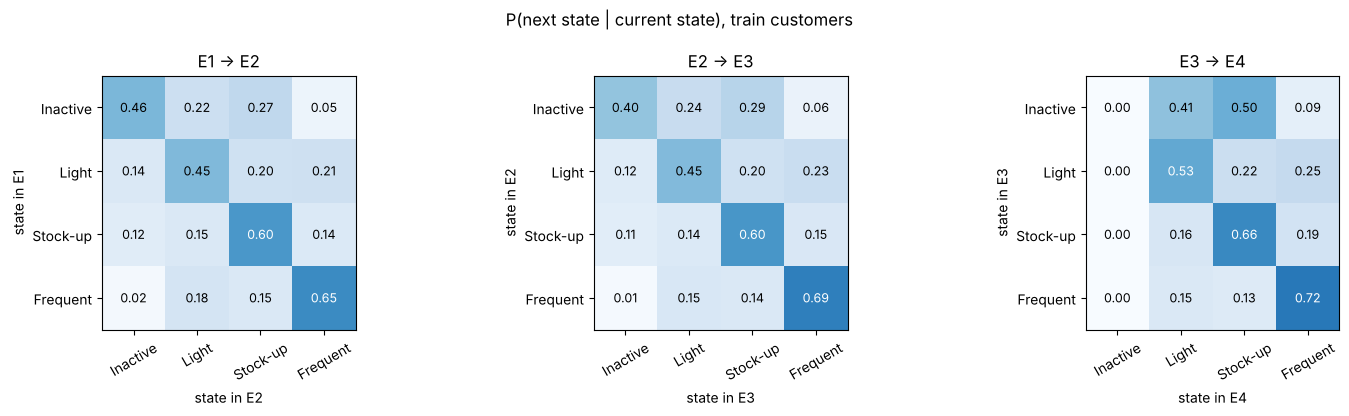

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (a, b) in zip(axes, PERIOD_PAIRS):
    tm = transition_matrix(a, b)
    im = ax.imshow(tm.values, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(4), STATE_ORDER, rotation=30); ax.set_yticks(range(4), STATE_ORDER)
    for i in range(4):
        for j in range(4):
            v = tm.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black", fontsize=9)
    ax.set(title=f"{a} → {b}", xlabel=f"state in {b}", ylabel=f"state in {a}")
fig.suptitle("P(next state | current state), train customers")
plt.tight_layout()
plt.savefig(FIG_DIR / "C_transition_matrices.png", dpi=130)
plt.show()

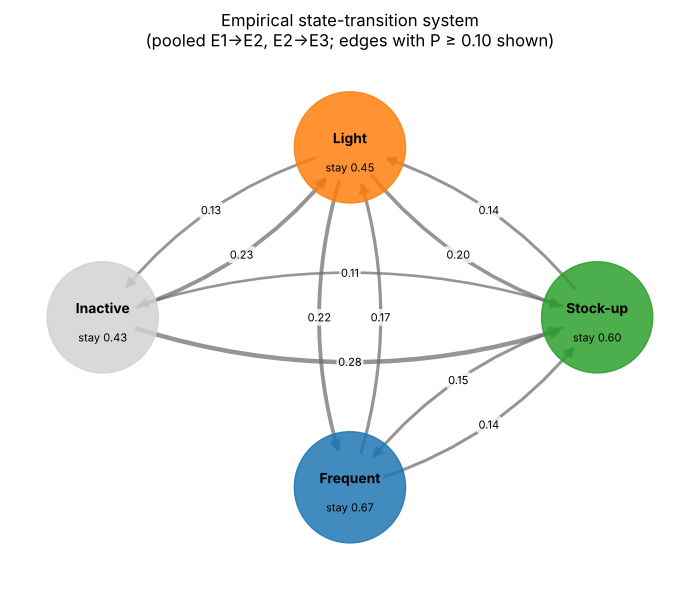

In [28]:
from matplotlib.patches import FancyArrowPatch, Circle

def draw_state_graph(P, ax, min_prob=0.10, title=""):
    pos = {"Inactive": (0, 0), "Light": (1.6, 1.1), "Stock-up": (3.2, 0), "Frequent": (1.6, -1.1)}
    colors = {"Inactive": "lightgrey", "Light": "tab:orange", "Stock-up": "tab:green", "Frequent": "tab:blue"}
    for s, (x, y) in pos.items():
        ax.add_patch(Circle((x, y), 0.36, color=colors[s], alpha=0.85, zorder=3))
        ax.text(x, y + 0.06, s, ha="center", va="center", fontsize=10, weight="bold", zorder=4)
        ax.text(x, y - 0.13, f"stay {P.loc[s, s]:.2f}", ha="center", va="center", fontsize=8, zorder=4)
    for a in STATE_ORDER:
        for b in STATE_ORDER:
            p = P.loc[a, b]
            if a == b or p < min_prob:
                continue
            arrow = FancyArrowPatch(pos[a], pos[b], connectionstyle="arc3,rad=0.18", arrowstyle="-|>",
                                    mutation_scale=14, lw=1 + 8 * p, color="dimgray", alpha=0.7,
                                    shrinkA=26, shrinkB=26, zorder=2)
            ax.add_patch(arrow)
            (x1, y1), (x2, y2) = pos[a], pos[b]
            # matplotlib's arc3 bends toward (dy, -dx); the curve's midpoint is half the control-point offset
            lx = (x1 + x2) / 2 + 0.5 * 0.18 * (y2 - y1)
            ly = (y1 + y2) / 2 - 0.5 * 0.18 * (x2 - x1)
            ax.text(lx, ly, f"{p:.2f}", fontsize=8, ha="center", va="center",
                    bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
    ax.set_xlim(-0.6, 3.8); ax.set_ylim(-1.7, 1.7); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(8, 6))
draw_state_graph(pooled, ax, title="Empirical state-transition system\n(pooled E1→E2, E2→E3; edges with P ≥ 0.10 shown)")
plt.tight_layout()
plt.savefig(FIG_DIR / "C_state_graph.png", dpi=130)
plt.show()

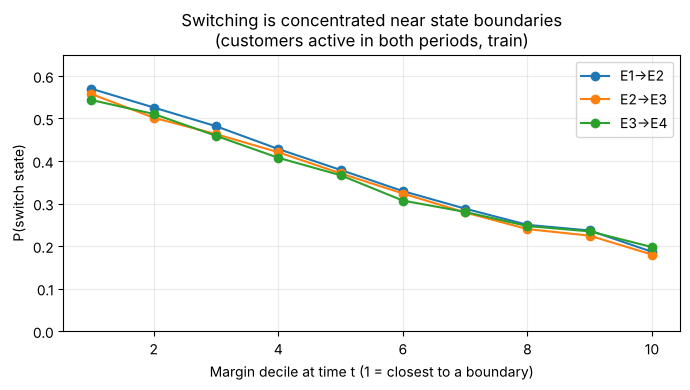

In [29]:
fig, ax = plt.subplots(figsize=(7, 4))
for t, col in switch_by_margin.items():
    ax.plot(switch_by_margin.index.astype(int), col.values, marker="o", label=t)
ax.set(xlabel="Margin decile at time t (1 = closest to a boundary)", ylabel="P(switch state)",
       title="Switching is concentrated near state boundaries\n(customers active in both periods, train)")
ax.set_ylim(0, 0.65); ax.grid(alpha=0.25); ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "C_switch_by_margin.png", dpi=130)
plt.show()

### §C · Interpretation

1. **States are persistent.** About 56% of customers are in the same state the next month, roughly double the ≈27–30% expected if
   states were reassigned at random. A customer's state carries real information about their next month.
2. **But few customers stay put for long.** Only 29% keep one state through all four periods; 46% change state two or three times.
   The three most common sequences are "always Frequent" (14%), "always Stock-up" (11%) and "always Light" (4%).
3. **Persistence differs by state.** Frequent is the stickiest (stay ≈ 0.67), then Stock-up (≈ 0.60); Light is the least stable (≈ 0.45),
   splitting its moves almost evenly between Stock-up, Frequent and Inactive. Light customers make only ~2 trips a month, so a single extra
   or missing trip, or one unusual basket, moves them.
4. **Inactive is a real, recurring state, not just "gone":** 57% of E1/E2-inactive customers are active the next month, mostly as Stock-up or Light.
   Frequent customers almost never go fully inactive (≈ 2%).
5. **Switching does *not* increase toward E4.** Among customers active in both periods, the stay rate is 0.633 → 0.641 → 0.647.
   Individual-level churn between states is roughly constant over the four months — consistent with §A's finding that the population
   distribution is stable.
6. **Much of the switching happens at the boundaries.** Customers in the closest-to-boundary decile switch 54–57% of the time; those deepest
   inside a state switch 18–20%. Requiring a margin of 0.25 on both sides keeps 63% of switches; a margin of 0.5 keeps only 39%.

**What this means.** Two kinds of "state change" are mixed together: *boundary noise* (small fluctuations that cross a line) and
*substantive moves* (a customer clearly leaves one region for another). Even far from any boundary, about one in five customers still switches,
so substantive change does occur. A transition model that treats every label change as meaningful would raise many false alarms — the same
problem the Dortmund project names for drift detection (robustness vs sensitivity). The margin threshold is a simple, interpretable dial for that trade-off.

**Limitations**
- The E3→E4 matrix is distorted by selection (no E4 Inactive); the pooled matrix and the graph therefore use E1→E2 and E2→E3 only.
- The margin is a distance in scaled log-feature space; a margin of 0.5 has no natural business meaning, only a relative one.
- We cannot fully separate noise from real change without finer-grained data (e.g. two 14-day halves of each period), which would be a natural extension.
- Transition probabilities describe *this* cohort over *these* four months; they are empirical frequencies, not a validated generative model.

## §D · Do existing drift measures line up with state switches?

**Question:** The project's earlier drift measures — per-customer behavior changes, behavioral instability, and category Jensen–Shannon (JS)
drift — were built to capture "behavioral change". Do customers who **switch state** actually score higher on them? And is any link real,
or produced by how much history we observe?

**Data:** training customers, transitions where the customer is active in both periods (so every measure is defined).

**Measures compared for each transition t → t+1**

| Measure | What it captures | Circular? |
|---|---|---|
| \|Δ log1p(transactions)\| | change in trip frequency | **Yes** — a state-defining feature |
| \|Δ log1p(avg basket spend)\| | change in basket size | **Yes** |
| \|Δ log1p(avg unique products)\| | change in basket variety | **Yes** |
| Category JS distance (t vs t+1) | change in *what* is bought | **No** — categories are not used to define states |

The first three are expected to separate switchers from stayers by construction; they are a reference point. Category JS is the real test.

**How separation is measured: AUC.** For a random switcher and a random stayer, the AUC is the probability that the switcher has the larger
drift value. 0.5 = no separation, 1.0 = perfect. It is a scale-free effect size, so measures in different units can be compared.

**Confounders handled by stratifying** (computing AUC within groups, then averaging weighted by group size):
- **Starting state** — Light customers switch far more than Frequent ones (§C), and may also differ in drift.
- **Observation depth** — the smaller of the two periods' category line counts, in quartiles. JS from a handful of lines is noisy (notebook 01, §8).

In [30]:
from sklearn.metrics import roc_auc_score

cust_period = pd.read_parquet(DATA_DIR / "processed" / "customer_period.parquet",
                              columns=["client_id", "period", "category_lines"])
period_lines = cust_period.pivot(index="client_id", columns="period", values="category_lines")
md_idx = model_data.set_index("client_id")

rows = []
for a, b in PERIOD_PAIRS:
    both = (train_states[a] != "Inactive") & (train_states[b] != "Inactive")
    ids = train_states.index[both]
    df = pd.DataFrame(index=ids)
    df["transition"] = f"{a}→{b}"
    df["state_t"] = train_states.loc[ids, a].astype(str).values
    df["state_t1"] = train_states.loc[ids, b].astype(str).values
    df["switched"] = df["state_t"] != df["state_t1"]
    df["margin_t"], df["margin_t1"] = train_margin.loc[ids, a].values, train_margin.loc[ids, b].values
    df["category_js"] = md_idx.loc[ids, f"category_drift_{a}_{b}"].values
    df["min_lines"] = np.minimum(period_lines.loc[ids, a], period_lines.loc[ids, b]).values
    for f in STATE_FEATURES:
        df[f"abs_change_{f}"] = np.abs(np.log1p(md_idx.loc[ids, f"{f}_{b}"]) - np.log1p(md_idx.loc[ids, f"{f}_{a}"])).values
    rows.append(df)
transitions = pd.concat(rows).rename_axis("client_id").reset_index()
transitions["depth_quartile"] = pd.qcut(transitions["min_lines"], 4, labels=["D1 sparse", "D2", "D3", "D4 deep"])

print("Transitions:", len(transitions), "| missing JS:", transitions["category_js"].isna().sum())
transitions.groupby("depth_quartile", observed=True)["min_lines"].agg(["min", "median", "max"])

Transitions: 259555 | missing JS: 0


,min,median,max
depth_quartile,,,
D1 sparse,1,5.0,8
D2,9,13.0,18
D3,19,25.0,33
D4 deep,34,50.0,549


In [31]:
MEASURES = ["abs_change_transactions", "abs_change_avg_basket_spend", "abs_change_avg_unique_products", "category_js"]

def auc(df, measure, target="switched"):
    return roc_auc_score(df[target], df[measure]) if df[target].nunique() == 2 else np.nan

def stratified_auc(df, measure, strata, target="switched"):
    g = df.groupby(strata, observed=True)
    aucs = g.apply(lambda x: auc(x, measure, target), include_groups=False)
    sizes = g.size()
    ok = aucs.notna()
    return (aucs[ok] * sizes[ok]).sum() / sizes[ok].sum()

auc_table = pd.DataFrame({
    "raw": {m: auc(transitions, m) for m in MEASURES},
    "within_start_state": {m: stratified_auc(transitions, m, ["state_t"]) for m in MEASURES},
    "within_state_and_depth": {m: stratified_auc(transitions, m, ["state_t", "depth_quartile"]) for m in MEASURES},
})
auc_table.round(3)

,raw,within_start_state,within_state_and_depth
abs_change_transactions,0.659,0.660,0.641
abs_change_avg_basket_spend,0.671,0.662,0.658
abs_change_avg_unique_products,0.685,0.681,0.687
category_js,0.641,0.610,0.538


In [32]:
# Why does JS lose its signal? Switching and JS both depend on observation depth.
print("Correlation(category JS, log1p(min lines)):",
      round(transitions["category_js"].corr(np.log1p(transitions["min_lines"])), 3))
js_by = transitions.pivot_table(index="depth_quartile", columns="switched", values="category_js",
                                aggfunc="mean", observed=True).rename(columns={False: "js_stayers", True: "js_switchers"})
depth_view = transitions.groupby("depth_quartile", observed=True).agg(
    switch_rate=("switched", "mean"),
    share_light_start=("state_t", lambda x: (x == "Light").mean())).join(js_by)
depth_view.round(3)

Correlation(category JS, log1p(min lines)): -0.739


,switch_rate,share_light_start,js_stayers,js_switchers
depth_quartile,,,,
D1 sparse,0.490,0.669,0.681,0.683
D2,0.538,0.338,0.528,0.521
D3,0.229,0.015,0.428,0.445
D4 deep,0.159,0.000,0.338,0.357


**Boundary vs confident switches.** §C showed many switches are boundary noise. If JS tracks *substantive* behavioral change, it should
separate **confident switches** (margin > 0.25 before and after) from stayers better than it separates all switches.

In [33]:
transitions["kind"] = np.select(
    [~transitions["switched"], (transitions["margin_t"] > 0.25) & (transitions["margin_t1"] > 0.25)],
    ["stay", "confident switch"], default="boundary switch")

display(transitions.groupby("kind")[MEASURES + ["min_lines"]].median().round(3))

conf = transitions[transitions["kind"] != "boundary switch"].assign(
    confident=lambda d: d["kind"] == "confident switch")
pd.DataFrame({
    "raw": {m: auc(conf, m, "confident") for m in MEASURES},
    "within_state_and_depth": {m: stratified_auc(conf, m, ["state_t", "depth_quartile"], "confident") for m in MEASURES},
}).round(3)

,abs_change_transactions,abs_change_avg_basket_spend,abs_change_avg_unique_products,category_js,min_lines
kind,,,,,
boundary switch,0.405,0.377,0.278,0.500,14.0
confident switch,0.560,0.591,0.446,0.551,10.0
stay,0.288,0.271,0.193,0.435,23.0


,raw,within_state_and_depth
abs_change_transactions,0.693,0.680
abs_change_avg_basket_spend,0.719,0.708
abs_change_avg_unique_products,0.735,0.744
category_js,0.667,0.550


**Behavioral instability (E4 vs history).** Instability summarizes how far E4 is from the customer's E1–E3 average
(mean absolute z-score of four recent deviations, standardized with **training** statistics, as in notebook 04). It is a whole-history measure,
so we compare it with (i) switching at E3→E4 and (ii) the total number of state changes over E1→E4.

In [34]:
deviation_features = ["transactions_recent_deviation", "total_spend_recent_deviation",
                      "avg_basket_spend_recent_deviation", "total_quantity_recent_deviation"]
train_all = model_data[model_data["split"] == "train"]
dev_stats = {f: (train_all[f].mean(), train_all[f].std()) for f in deviation_features}
model_data["behavioral_instability_clean"] = pd.DataFrame(
    {f: (model_data[f] - mu) / sd for f, (mu, sd) in dev_stats.items()}).abs().mean(axis=1)

inst = train_states.copy()
inst["instability"] = model_data.set_index("client_id").loc[inst.index, "behavioral_instability_clean"]
inst["switched_E3_E4"] = (inst["E3"] != inst["E4"]) & (inst["E3"] != "Inactive")
inst["n_changes"] = sum((inst[a] != inst[b]).astype(int) for a, b in PERIOD_PAIRS)
inst["history_lines"] = md_idx.loc[inst.index, "historical_category_lines"]
inst["depth_quartile"] = pd.qcut(inst["history_lines"], 4, labels=["D1 sparse", "D2", "D3", "D4 deep"])

e3_active = inst[inst["E3"] != "Inactive"].assign(E3=lambda d: d["E3"].astype(str))
print("AUC, instability vs E3→E4 switch (E3-active):",
      round(auc(e3_active, "instability", "switched_E3_E4"), 3),
      "| within E3 state & depth:",
      round(stratified_auc(e3_active, "instability", ["E3", "depth_quartile"], "switched_E3_E4"), 3))
inst.groupby("n_changes")["instability"].describe()[["count", "25%", "50%", "75%"]].round(3)

AUC, instability vs E3→E4 switch (E3-active): 0.536 | within E3 state & depth: 0.587


,count,25%,50%,75%
n_changes,,,,
0,30628.0,0.303,0.488,0.783
1,27244.0,0.289,0.509,0.839
2,33602.0,0.270,0.434,0.687
3,15147.0,0.274,0.440,0.685


### Consequence for an outcome: depth-adjusted category drift and treatment response

This analysis was originally in notebook 01 and is moved here because it is a drift-measurement result. It uses the randomized experiment:
within each group, treated-minus-control purchase rate is an unbiased treatment-effect estimate. No model is fitted, so using all uplift
customers does not leak anything into later modeling.

1. **Raw:** quartiles of history→E4 category drift.
2. **Depth-adjusted:** split customers into history-depth quartiles first, form drift quartiles *within* each depth group, then pool —
   so every drift quartile has the same mix of history depth.

In [35]:
def group_effects(df, group_col):
    rows = []
    for g, d in df.groupby(group_col, observed=True):
        t, c = d.loc[d["treatment_flg"] == 1, "target"], d.loc[d["treatment_flg"] == 0, "target"]
        ate = t.mean() - c.mean()
        se = np.sqrt(t.mean() * (1 - t.mean()) / len(t) + c.mean() * (1 - c.mean()) / len(c))
        rows.append({"group": g, "n": len(d), "median_history_lines": d["historical_category_lines"].median(),
                     "mean_drift": d["category_drift_history_E4"].mean(), "control_rate_%": 100 * c.mean(),
                     "ATE_pp": 100 * ate, "CI_low": 100 * (ate - 1.96 * se), "CI_high": 100 * (ate + 1.96 * se)})
    return pd.DataFrame(rows)

LABELS = ["Q1 stable mix", "Q2", "Q3", "Q4 high mix change"]
cat = model_data[model_data["category_drift_history_E4"].notna()].copy()
cat["raw_drift_q"] = pd.qcut(cat["category_drift_history_E4"], 4, labels=LABELS)
cat["depth_group"] = pd.qcut(cat["historical_category_lines"], 4, labels=False, duplicates="drop")
cat["adjusted_drift_q"] = (cat.groupby("depth_group")["category_drift_history_E4"]
                              .transform(lambda x: pd.qcut(x, 4, labels=False)).map(dict(enumerate(LABELS))))
cat["adjusted_drift_q"] = pd.Categorical(cat["adjusted_drift_q"], categories=LABELS, ordered=True)

print("RAW drift quartiles")
display(group_effects(cat, "raw_drift_q").round(2))
print("DEPTH-ADJUSTED drift quartiles")
group_effects(cat, "adjusted_drift_q").round(2)

RAW drift quartiles


,group,n,median_history_lines,mean_drift,control_rate_%,ATE_pp,CI_low,CI_high
0,Q1 stable mix,47407,127.0,0.27,80.41,2.07,1.37,2.77
1,Q2,47406,77.0,0.38,69.17,2.20,1.37,3.02
2,Q3,47406,48.0,0.50,56.71,3.48,2.59,4.36
3,Q4 high mix change,47407,24.0,0.71,40.39,4.87,3.98,5.76


DEPTH-ADJUSTED drift quartiles


,group,n,median_history_lines,mean_drift,control_rate_%,ATE_pp,CI_low,CI_high
0,Q1 stable mix,47407,61.0,0.31,69.57,3.11,2.29,3.92
1,Q2,47406,61.0,0.41,65.23,2.97,2.12,3.82
2,Q3,47406,60.0,0.49,60.97,2.88,2.00,3.75
3,Q4 high mix change,47407,60.0,0.65,50.81,3.87,2.97,4.77


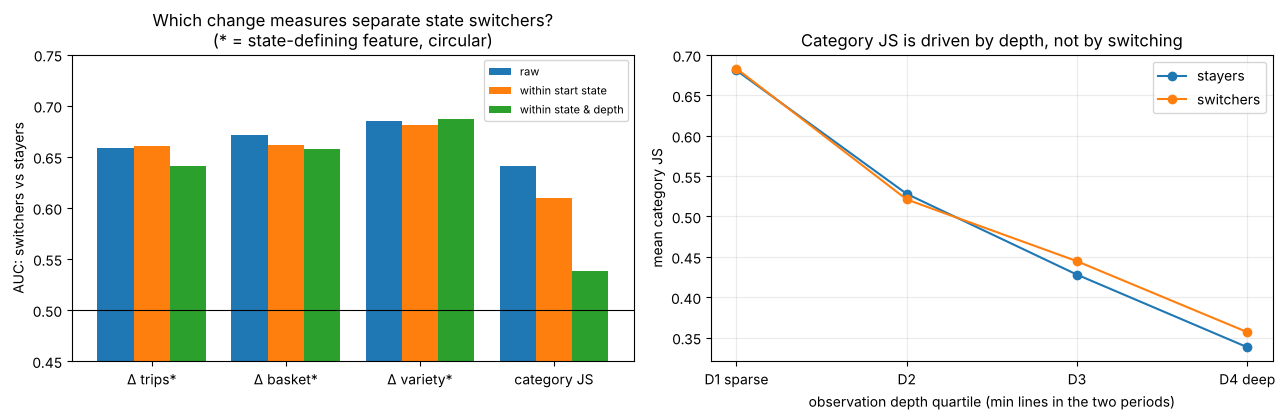

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))

x = np.arange(len(MEASURES))
labels = ["Δ trips*", "Δ basket*", "Δ variety*", "category JS"]
for i, (col, name) in enumerate([("raw", "raw"), ("within_start_state", "within start state"),
                                 ("within_state_and_depth", "within state & depth")]):
    axes[0].bar(x + (i - 1) * 0.27, auc_table[col].values, width=0.27, label=name)
axes[0].axhline(0.5, color="black", lw=0.8)
axes[0].set_xticks(x, labels); axes[0].set_ylim(0.45, 0.75)
axes[0].set(ylabel="AUC: switchers vs stayers", title="Which change measures separate state switchers?\n(* = state-defining feature, circular)")
axes[0].legend(fontsize=8)

dv = depth_view.reset_index()
axes[1].plot(dv["depth_quartile"].astype(str), dv["js_stayers"], marker="o", label="stayers")
axes[1].plot(dv["depth_quartile"].astype(str), dv["js_switchers"], marker="o", label="switchers")
axes[1].set(ylabel="mean category JS", xlabel="observation depth quartile (min lines in the two periods)",
            title="Category JS is driven by depth, not by switching")
axes[1].legend(); axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.savefig(FIG_DIR / "D_drift_vs_switching.png", dpi=130)
plt.show()

### §D · Interpretation

1. **Category drift looks related to switching — but mostly because of observation depth.** Raw AUC 0.64 falls to 0.61 within starting
   state and to **0.54 within state × depth**, close to no separation. Inside each depth quartile, switchers and stayers have almost the same
   mean JS (e.g. 0.683 vs 0.681 in the sparsest quartile). JS correlates −0.74 with log(line count), and sparse customers both switch more
   (49–54% vs 16–23%) and are mostly Light. Changing *what* you buy and changing *how* you shop (frequency/basket size) are largely separate.
2. **Even the circular measures separate switchers only moderately** (AUC ≈ 0.64–0.69). A small change near a boundary flips the label while
   a large change deep inside a state does not. *State switching and "amount of change" are different things* — a state is a coarse,
   thresholded view of behavior.
3. **Confident switches look more like real change.** Separating confident switches from stayers raises every circular AUC (to 0.68–0.74),
   but category JS still stays near 0.55 after stratification. Confident switchers also have *fewer* category lines (median 10 vs 23 for
   stayers), so even "confident" switches are concentrated among sparsely observed customers.
4. **Behavioral instability barely tracks switching** (AUC 0.54 for E3→E4; 0.59 within state & depth), and customers with 2–3 state
   changes have *lower* median instability than those with none. Instability compares E4 with the E1–E3 *average*, so a customer who
   oscillates (Frequent → Light → Frequent) averages out. Instability measures departure from a baseline; switching counts crossings of a
   threshold. They answer different questions.
5. **The outcome consequence (moved from notebook 01) reproduces exactly.** With raw drift quartiles, the treatment effect rises steadily
   from 2.1 to 4.9 pp, which looks like "customers changing their product mix respond more to messages". Once quartiles are formed within
   history-depth groups (median history ≈ 60 lines in every quartile), the pattern becomes flat and non-monotonic (3.1, 3.0, 2.9, 3.9 pp).
   Baseline purchase rates still differ (70% → 51%), so drift is related to *who* the customer is, but most of the apparent link to *treatment
   response* came from history depth.

**What this means for the research question.** A drift metric can look informative while mostly measuring how much data we have about a
customer. Before using any drift score to decide that "behavior changed", it must be compared against customers with similar observation
depth. This is a concrete instance of the Dortmund project's concern about noise and uncertainty in real-world drift detection.

**Limitations**
- AUC measures ranking separation only; it says nothing about the size of a typical difference.
- Depth quartiles are coarse; some confounding by depth can remain within a quartile.
- The confident/boundary split uses one arbitrary margin threshold (0.25), chosen for illustration in §C, not tuned.
- Category JS is only available for customers with purchases in both periods; the analysis covers active-to-active transitions only.

## Save states for notebook 03

One row per customer in the enrolled cohort: state in each period, boundary margin in each active period, and split.

In [37]:
states_wide = long.pivot(index="client_id", columns="period", values="state")
states_wide.columns = [f"state_{p}" for p in states_wide.columns]
margin_wide = long.pivot(index="client_id", columns="period", values="margin")
margin_wide.columns = [f"margin_{p}" for p in margin_wide.columns]
states_out = (states_wide.astype(str).join(margin_wide).reset_index()
              .merge(cohort_data[["client_id", "split"]], on="client_id"))
states_out.to_parquet(DATA_DIR / "processed" / "customer_states.parquet", index=False)
print(states_out.shape)
states_out.head()

(177600, 10)


,client_id,state_E1,state_E2,state_E3,state_E4,margin_E1,margin_E2,margin_E3,margin_E4,split
0,000012768d,Stock-up,Inactive,Inactive,Stock-up,2.164595,NaN,NaN,2.006563,val
1,000036f903,Frequent,Frequent,Frequent,Frequent,1.841207,0.061422,1.743528,1.428422,val
2,00010925a5,Frequent,Light,Frequent,Frequent,0.398446,0.151520,0.007438,1.144037,train
3,0001f552b0,Stock-up,Stock-up,Light,Frequent,0.623370,1.900390,0.296397,0.907147,train
4,00020e7b18,Stock-up,Stock-up,Stock-up,Stock-up,1.699766,2.185367,1.443201,1.665192,test
